# M02 — Expanded EDA: Predicting Corporate Bankruptcy Risk
**QM 47400 · Group 22** — Jeffrey Wan, Nitya Jhaveri, Christopher Weng, Kyle Cuson

This notebook produces every number and figure in `22_outline.pdf`. It is organized around
the course rules:

| Rule | Where it is enforced |
|---|---|
| nb01 — split before exploring; the test set stays locked | §3 splits by year **before** any feature–target analysis; §4–§9 use **training years only**; test-year labels and features are never summarized |
| nb01 — EDA checklist (types, missingness, descriptives, target, distributions, correlations) | §1 audit, §4 checklist, §9 correlations |
| nb02 — audit function; "fit on train only" | §1 `audit_report()`; every fitted step lives in the §10 pipeline |
| nb02/nb09 — **all preprocessing inside one `Pipeline`** | §10: ratios, logs, changes, Altman Z, winsorizing, imputation, scaling, one-hot encoding |
| nb03/nb07 — baselines + cost-aware, imbalance-aware metrics | §10 scorers (PR-AUC, recall in top 5%, expected cost) vs no-skill and Altman Z baselines |
| nb08/nb09 — honest CV | §10 time-ordered (expanding-window) folds inside the training years |

**Variable names.** The Kaggle columns X1–X18 are renamed on load to their accounting names
(e.g. X10 → total_assets); every feature has a plain-English name.

**Data.** Kaggle `data/american_bankruptcy.csv`. SIC industry codes are merged from the authors'
public GitHub release (same firm IDs and years).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, make_scorer
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RANDOM_SEED = 474
pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)
os.makedirs("figures", exist_ok=True)

# Chart styling (validated categorical slots; recessive ink for text + grid)
C_ALIVE, C_FAIL, C_THIRD, C_LOCK = "#2a78d6", "#eb6834", "#1baf7a", "#d9d8d3"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "bold",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False, "figure.dpi": 110,
    "text.color": INK,
})

## 1. Load and structural audit (nb01 §3 / nb02 §3)
Structural checks only — types, missingness, duplicates, accounting identities. Nothing here
looks at the relationship between features and the target, so it is safe on the full file.

In [2]:
KAGGLE_PATH = "data/american_bankruptcy.csv"
GH_URL = "https://raw.githubusercontent.com/sowide/bankruptcy_dataset/main/american_bankruptcy_dataset.csv"

df = pd.read_csv(KAGGLE_PATH)
try:  # optional industry codes (SIC division), keyed on the same firm ID + year
    div = pd.read_csv(GH_URL, usecols=["company_name", "fyear", "Division"]).rename(columns={"fyear": "year"})
    div["year"] = div["year"].astype(int)
    df = df.merge(div, on=["company_name", "year"], how="left")
except Exception as e:
    df["Division"] = np.nan
    print("industry codes not attached:", e)

NAMES = {"X1":"current_assets","X2":"cogs","X3":"dep_amort","X4":"ebitda","X5":"inventory",
         "X6":"net_income","X7":"receivables","X8":"market_value","X9":"net_sales",
         "X10":"total_assets","X11":"lt_debt","X12":"ebit","X13":"gross_profit",
         "X14":"current_liab","X15":"retained_earn","X16":"total_revenue",
         "X17":"total_liab","X18":"total_opex"}
df = df.rename(columns=NAMES)
print(df.shape)
df.info()

(78682, 22)
<class 'pandas.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   company_name    78682 non-null  str    
 1   status_label    78682 non-null  str    
 2   year            78682 non-null  int64  
 3   current_assets  78682 non-null  float64
 4   cogs            78682 non-null  float64
 5   dep_amort       78682 non-null  float64
 6   ebitda          78682 non-null  float64
 7   inventory       78682 non-null  float64
 8   net_income      78682 non-null  float64
 9   receivables     78682 non-null  float64
 10  market_value    78682 non-null  float64
 11  net_sales       78682 non-null  float64
 12  total_assets    78682 non-null  float64
 13  lt_debt         78682 non-null  float64
 14  ebit            78682 non-null  float64
 15  gross_profit    78682 non-null  float64
 16  current_liab    78682 non-null  float64
 17  retained_earn   78682 non-null

In [3]:
def audit_report(data, cols):
    """nb02-style audit: one row per column."""
    return pd.DataFrame({
        "dtype": data[cols].dtypes.astype(str),
        "missing": data[cols].isna().sum(),
        "n_unique": data[cols].nunique(),
        "n_zero": (data[cols] == 0).sum(),
        "n_negative": (data[cols].select_dtypes("number") < 0).sum().reindex(cols),
    })

audit_report(df, list(NAMES.values()) + ["year", "status_label", "Division"])

,dtype,missing,n_unique,n_zero,n_negative
current_assets,float64,0,65895,0,6.0
cogs,float64,0,65690,306,6.0
dep_amort,float64,0,36010,633,0.0
ebitda,float64,0,59060,3,23012.0
inventory,float64,0,38898,19701,0.0
net_income,float64,0,55550,7,34001.0
receivables,float64,0,49577,2205,1.0
market_value,float64,0,77580,0,0.0
net_sales,float64,0,68596,0,13.0
total_assets,float64,0,71521,0,0.0


In [4]:
tol = dict(rtol=0.005, atol=0.002)
checks = {
    "gross_profit = revenue − COGS": np.isclose(df.gross_profit, df.total_revenue - df.cogs, **tol),
    "EBIT = EBITDA − D&A": np.isclose(df.ebit, df.ebitda - df.dep_amort, **tol),
    "total_assets ≥ current_assets": df.total_assets >= df.current_assets - 1e-6,
    "total_liab ≥ current_liab": df.total_liab >= df.current_liab - 1e-6,
}
yrs = df.groupby("company_name").year.agg(["min", "max", "count"])
structural = pd.Series({
    "rows": len(df), "unique firm IDs": df.company_name.nunique(), "years": f"{df.year.min()}–{df.year.max()}",
    "missing cells": int(df[list(NAMES.values())].isna().sum().sum()),
    "duplicate firm-years": int(df.duplicated(["company_name", "year"]).sum()),
    "net_sales == total_revenue (share)": float(np.isclose(df.net_sales, df.total_revenue).mean()),
    **{f"identity holds: {k}": round(float(np.mean(v)), 4) for k, v in checks.items()},
    "rows failing ≥1 identity": int((~np.column_stack(list(checks.values())).all(axis=1)).sum()),
    "firms with a gap in their year sequence": int(((yrs["max"] - yrs["min"] + 1) != yrs["count"]).sum()),
    "rows missing an industry code": int(df.Division.isna().sum()),
}, name="value")
structural.to_frame()

,value
rows,78682
unique firm IDs,8971
years,1999–2018
missing cells,0
duplicate firm-years,0
net_sales == total_revenue (share),1.0
identity holds: gross_profit = revenue − COGS,1.0
identity holds: EBIT = EBITDA − D&A,1.0
identity holds: total_assets ≥ current_assets,1.0
identity holds: total_liab ≥ current_liab,1.0


## 2. Target definition — what does `status_label = failed` mean?
The README says the fiscal year *before* a Chapter 7/11 filing is labeled bankrupt, but in the
file **every** year of an eventually-failing firm is `failed`. For a one-year-ahead goal we set
**y = 1 only on a failed firm's last reported year**; its earlier years were not followed by a
filing within a year, so y = 0. (This is target construction, not preprocessing: it defines
what we predict and is applied identically to every row.)

In [5]:
df = df.sort_values(["company_name", "year"]).reset_index(drop=True)
fails_per_firm = df.groupby("company_name").status_label.agg(lambda s: (s == "failed").sum())
failed_firms = fails_per_firm[fails_per_firm > 0].index
last_year = df.groupby("company_name").year.transform("max")
df["y"] = ((df.status_label == "failed") & (df.year == last_year)).astype(int)
df["ever_failed"] = df.company_name.isin(failed_firms).astype(int)
df["years_to_failure"] = np.where(df.ever_failed == 1, last_year - df.year, np.nan)
print(f"rows labeled failed: {(df.status_label=='failed').sum():,} ({(df.status_label=='failed').mean():.2%}); "
      f"firms ever failed: {len(failed_firms)}; firms mixing alive/failed rows: "
      f"{df[df.ever_failed==1].groupby('company_name').status_label.nunique().gt(1).sum()}")
print(f"one-year-ahead positives (all years): {df.y.sum():,} ({df.y.mean():.2%})")

rows labeled failed: 5,220 (6.63%); firms ever failed: 609; firms mixing alive/failed rows: 0
one-year-ahead positives (all years): 609 (0.77%)


## 3. Data assembly and the chronological split (done BEFORE any exploration)
Data assembly = putting information that is *known at prediction time* on the row. A firm's
prior-year annual report is public when year *t* is scored, so we attach its **raw** prior-year
figures as extra columns (only when that report is exactly year *t−1*). No transformation is
computed here — ratios, changes, logs, etc. are all built inside the §10 pipeline.

In [6]:
RAW = [c for c in NAMES.values() if c != "net_sales"]          # drop the duplicate column
LAG_SRC = ["total_liab", "total_assets", "net_income", "total_revenue", "market_value"]
prev = df.groupby("company_name")[LAG_SRC + ["year"]].shift(1)
adjacent = (df.year - prev.year) == 1
for c in LAG_SRC:
    df[f"prev_{c}"] = prev[c].where(adjacent)
INPUT_COLS = RAW + [f"prev_{c}" for c in LAG_SRC] + ["Division"]

def split_of(y):
    return "train" if y <= 2011 else ("validation" if y <= 2014 else "test")
df["split"] = df.year.map(split_of)

train = df[df.split == "train"].copy()
valid = df[df.split == "validation"].copy()
test_locked = df[df.split == "test"][["company_name", "year"] + INPUT_COLS]   # labels withheld
print("rows per split:", df.split.value_counts().reindex(["train", "validation", "test"]).to_dict())

# nb01 split sanity check on the splits we are allowed to look at (test labels stay locked)
sanity = pd.DataFrame({s: {"firm_years": len(d), "firms": d.company_name.nunique(),
                           "failures": int(d.y.sum()), "rate": d.y.mean()}
                       for s, d in [("train", train), ("validation", valid)]}).T
sanity

rows per split: {'train': 55927, 'validation': 10473, 'test': 12282}


,firm_years,firms,failures,rate
train,55927.0,7719.0,403.0,0.0072
validation,10473.0,4074.0,87.0,0.0083


## 4. EDA checklist on the TRAINING years (nb01 §3)
### 4.1 Descriptive statistics and target distribution

In [7]:
Xtr_raw, ytr = train[INPUT_COLS], train.y
desc = train[RAW].describe(percentiles=[0.01, 0.5, 0.99]).T
desc["skew"] = train[RAW].skew()
desc.round(2)

,count,mean,std,min,1%,50%,99%,max,skew
current_assets,55927.0,672.28,2755.53,-0.01,0.08,83.88,10454.74,85963.00,12.24
cogs,55927.0,1292.86,7326.14,-366.64,0.05,88.88,21590.41,346775.00,22.59
dep_amort,55927.0,92.64,501.44,0.00,0.00,6.67,1389.74,21577.00,19.25
ebitda,55927.0,289.90,1613.94,-7236.00,-86.90,12.42,4941.00,78669.00,18.43
inventory,55927.0,158.92,793.66,0.00,0.00,6.55,2738.16,40714.00,20.41
net_income,55927.0,90.08,1126.60,-98696.00,-572.91,1.41,2353.01,104821.00,7.03
receivables,55927.0,227.24,1054.89,-0.01,0.00,19.58,3819.66,38642.00,15.49
market_value,55927.0,2496.36,13404.16,0.00,0.54,177.32,44136.97,504239.58,15.11
total_assets,55927.0,2143.10,9558.72,0.00,0.27,173.13,35065.96,331052.00,13.51
lt_debt,55927.0,489.60,2038.79,0.00,0.00,5.59,9109.88,64720.00,10.92


In [8]:
by_year = train.groupby("year").agg(n=("y", "size"), fail=("y", "sum"), rate=("y", "mean"))
print("training-year failure rate range:", f"{by_year.rate.min():.2%} ({by_year.rate.idxmin()}) – "
      f"{by_year.rate.max():.2%} ({by_year.rate.idxmax()})")
by_year

training-year failure rate range: 0.06% (1999) – 1.50% (2008)


,n,fail,rate
year,,,
1999,5308,3,0.0006
2000,5226,7,0.0013
2001,4897,10,0.0020
2002,4651,17,0.0037
2003,4417,29,0.0066
2004,4348,46,0.0106
2005,4205,40,0.0095
2006,4128,51,0.0124
2007,4009,59,0.0147


### 4.2 Feature distributions (raw vs log) — all raw variables
Signed log `sign(x)·log(1+|x|)` is used for display so negative items (net income, EBIT,
retained earnings) are kept.

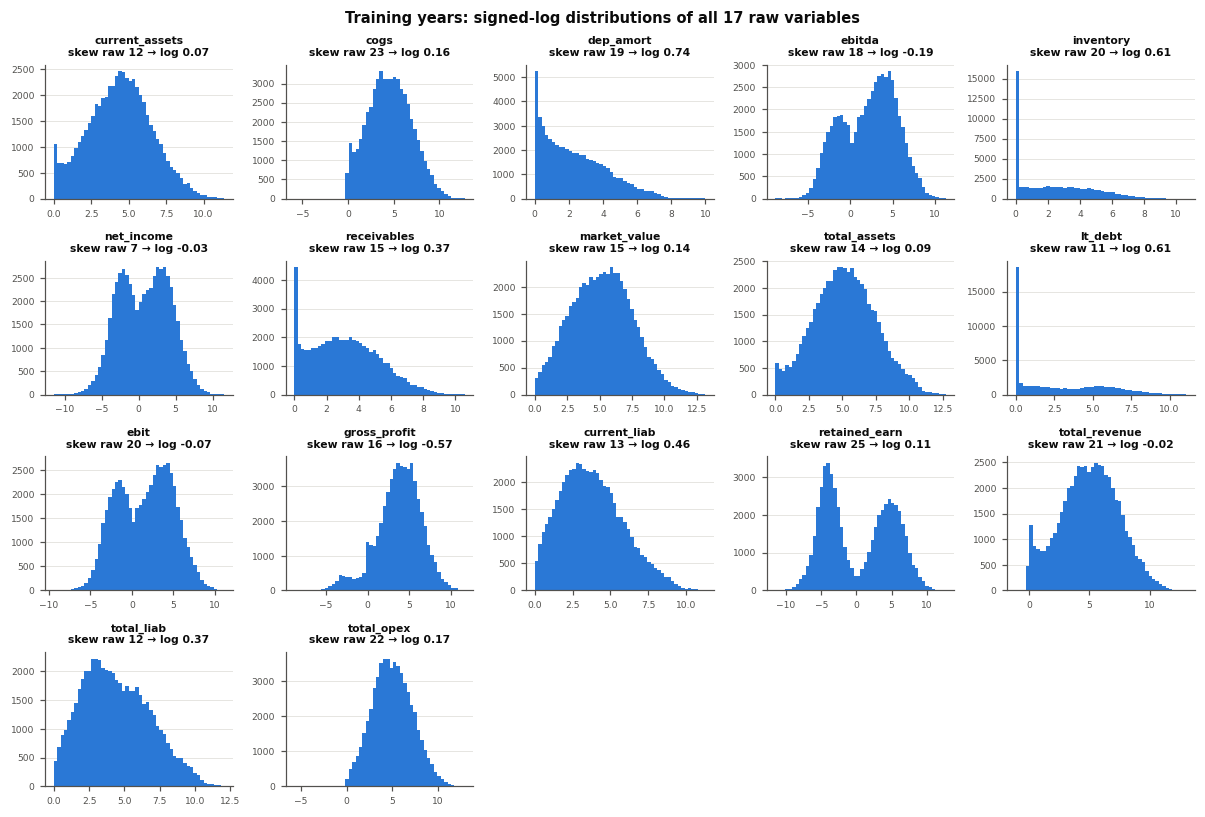

In [9]:
slog = lambda x: np.sign(x) * np.log1p(np.abs(x))
fig, axes = plt.subplots(4, 5, figsize=(11, 7.5))
for ax, c in zip(axes.flat, RAW):
    ax.hist(slog(train[c]), bins=50, color=C_ALIVE)
    ax.set_title(f"{c}\nskew raw {train[c].skew():.0f} → log {slog(train[c]).skew():.2f}", fontsize=7)
    ax.tick_params(labelsize=6); ax.grid(axis="x", visible=False)
for ax in axes.flat[len(RAW):]:
    ax.axis("off")
fig.suptitle("Training years: signed-log distributions of all 17 raw variables", fontweight="bold")
fig.tight_layout()
fig.savefig("figures/figA_all_distributions.png", dpi=200, bbox_inches="tight")

## 5. The feature builder (stateless — the same function the pipeline uses)
`build_features` learns nothing from data; it is row-wise arithmetic on the raw and prior-year
columns. In §10 it runs inside the `Pipeline` as a `FunctionTransformer`. Here we *call* it on
the training rows only to explore what it produces.

In [10]:
def _div(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        out = np.where(np.abs(b) > 1e-9, a / b, np.nan)
    return out

def build_features(X):
    X = X.copy()
    F = pd.DataFrame(index=X.index)
    F["Working capital / assets"]     = _div(X.current_assets - X.current_liab, X.total_assets)   # Altman 1
    F["Retained earnings / assets"]     = _div(X.retained_earn, X.total_assets)                     # Altman 2
    F["EBIT / assets"]   = _div(X.ebit, X.total_assets)                              # Altman 3
    F["Market value / liabilities"]     = _div(X.market_value, X.total_liab)                        # Altman 4
    F["Sales / assets"]  = _div(X.total_revenue, X.total_assets)                     # Altman 5
    F["Liabilities / assets"]     = _div(X.total_liab, X.total_assets)
    F["Long-term debt / assets"]    = _div(X.lt_debt, X.total_assets)
    F["Current ratio"]     = _div(X.current_assets, X.current_liab)
    F["Net income / assets"]     = _div(X.net_income, X.total_assets)
    F["Gross margin"]    = _div(X.gross_profit, X.total_revenue)
    F["EBITDA / liabilities"] = _div(X.ebitda, X.total_liab)
    F["Log total assets"]    = np.log1p(X.total_assets.clip(lower=0))
    F["Log market value"]    = np.log1p(X.market_value.clip(lower=0))
    F["Change in liabilities / assets"]   = F["Liabilities / assets"] - _div(X.prev_total_liab, X.prev_total_assets)
    F["Change in net income / assets"]   = F["Net income / assets"] - _div(X.prev_net_income, X.prev_total_assets)
    F["Sales growth"] = _div(X.total_revenue - X.prev_total_revenue, np.abs(X.prev_total_revenue))
    F["Market value growth"] = _div(X.market_value - X.prev_market_value, np.abs(X.prev_market_value))
    F["Altman Z"]  = 1.2*F["Working capital / assets"] + 1.4*F["Retained earnings / assets"] + 3.3*F["EBIT / assets"] + 0.6*F["Market value / liabilities"] + 1.0*F["Sales / assets"]
    F = F.replace([np.inf, -np.inf], np.nan)
    if "Division" in X:
        F["Division"] = X["Division"].fillna("Unknown").astype(str)
    return F

Ftr = build_features(Xtr_raw)
NUM_FEATS = [c for c in Ftr.columns if c not in ("Division", "Altman Z")]
q = Ftr[NUM_FEATS].quantile([0.01, 0.99])
extreme = ((Ftr[NUM_FEATS] < q.loc[0.01]) | (Ftr[NUM_FEATS] > q.loc[0.99])).any(axis=1).mean()
print(f"train rows with total assets < $1M: {(train.total_assets < 1).sum():,}")
print(f"train rows with ≥1 feature outside its 1st–99th pct: {extreme:.1%}")
Ftr[NUM_FEATS].isna().mean().round(3).sort_values(ascending=False).head(6).to_frame("missing share (train)")

train rows with total assets < $1M: 1,389
train rows with ≥1 feature outside its 1st–99th pct: 15.3%


,missing share (train)
Change in liabilities / assets,0.148
Sales growth,0.148
Change in net income / assets,0.148
Market value growth,0.148
Working capital / assets,0.000
Retained earnings / assets,0.000


## 6. Which features separate failures? (training years)
Univariate ROC-AUC, oriented so > 0.5 means separation. A screening view only — final importances
come from the cross-validated pipelines at M06.

In [11]:
rows = []
for c in NUM_FEATS + ["Altman Z"]:
    m = Ftr[c].notna()
    auc = roc_auc_score(ytr[m], Ftr.loc[m, c])
    rows.append({"feature": "Altman Z (1968)" if c == "Altman Z" else c, "AUC": max(auc, 1 - auc),
                 "higher →": "risk ↑" if auc > 0.5 else "risk ↓",
                 "median alive": Ftr.loc[m & (ytr == 0), c].median(),
                 "median failed": Ftr.loc[m & (ytr == 1), c].median()})
uni = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
uni.round(3)

,feature,AUC,higher →,median alive,median failed
0,Market value / liabilities,0.800,risk ↓,2.227,0.323
1,Liabilities / assets,0.769,risk ↑,0.492,0.878
2,Altman Z (1968),0.760,risk ↓,2.812,-0.362
3,Net income / assets,0.727,risk ↓,0.018,-0.216
4,Current ratio,0.725,risk ↓,1.915,0.959
5,Market value growth,0.722,risk ↓,0.026,-0.444
6,Log market value,0.722,risk ↓,5.198,3.321
7,Change in liabilities / assets,0.721,risk ↑,0.002,0.131
8,Working capital / assets,0.709,risk ↓,0.218,-0.012
9,EBITDA / liabilities,0.695,risk ↓,0.162,-0.015


## 7. Altman Z zones and industry (training years)

In [12]:
zone = pd.cut(Ftr["Altman Z"], [-np.inf, 1.81, 2.99, np.inf],
              labels=["Distress (<1.81)", "Grey (1.81–2.99)", "Safe (>2.99)"])
zt = train.groupby(zone, observed=True).agg(firm_years=("y", "size"), failures=("y", "sum"), rate=("y", "mean"))
zt["share of all failures"] = zt.failures / zt.failures.sum()
zt

,firm_years,failures,rate,share of all failures
Altman Z,,,,
Distress (<1.81),19855,304,0.0153,0.7543
Grey (1.81–2.99),9652,49,0.0051,0.1216
Safe (>2.99),26420,50,0.0019,0.1241


In [13]:
DIV = {"A":"Agri/Forestry","B":"Mining","C":"Construction","D":"Manufacturing","E":"Transport/Utilities",
       "F":"Wholesale","G":"Retail","H":"Finance/RE","I":"Services","J":"Public admin"}
ind = train.groupby("Division").agg(firm_years=("y", "size"), failures=("y", "sum"), rate=("y", "mean"))
ind.index = ind.index.map(DIV)
ind.sort_values("rate", ascending=False).round(4)

,firm_years,failures,rate
Division,,,
Retail,4030,48,0.0119
Agri/Forestry,203,2,0.0099
Mining,2841,26,0.0092
Transport/Utilities,5279,47,0.0089
Manufacturing,27005,197,0.0073
Finance/RE,1508,11,0.0073
Services,12426,61,0.0049
Wholesale,2127,9,0.0042
Construction,497,2,0.0040


## 8. How early does distress show up? (event time, training years)

In [14]:
KEY = ["Liabilities / assets", "EBIT / assets", "Market value / liabilities", "Working capital / assets"]
ev = Ftr.loc[train.ever_failed == 1, KEY].assign(ytf=train.loc[train.ever_failed == 1, "years_to_failure"])
traj = ev[ev.ytf <= 5].groupby("ytf")[KEY].median().sort_index(ascending=False)
alive_ref = Ftr.loc[train.ever_failed == 0, KEY].median()
print("never-failed firms (median):", alive_ref.round(3).to_dict())
traj.round(3)

never-failed firms (median): {'Liabilities / assets': 0.486, 'EBIT / assets': 0.051, 'Market value / liabilities': 2.299, 'Working capital / assets': 0.225}


,Liabilities / assets,EBIT / assets,Market value / liabilities,Working capital / assets
ytf,,,,
5.0,0.575,0.013,1.361,0.136
4.0,0.634,0.001,1.016,0.127
3.0,0.632,0.001,1.135,0.116
2.0,0.669,-0.005,0.912,0.134
1.0,0.774,-0.018,0.637,0.095
0.0,0.878,-0.068,0.323,-0.012


## 9. Multicollinearity and drift (training years)

In [15]:
corr = Ftr[NUM_FEATS].corr(method="spearman")
corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().abs().sort_values(ascending=False).head(8).round(2)

Working capital / assets    Current ratio           0.92
EBIT / assets               EBITDA / liabilities    0.89
Log total assets            Log market value        0.88
EBIT / assets               Net income / assets     0.88
Net income / assets         EBITDA / liabilities    0.83
Liabilities / assets        Current ratio           0.72
Market value / liabilities  Liabilities / assets    0.72
Retained earnings / assets  EBIT / assets           0.67
dtype: float64

In [16]:
# Drift WITHIN the training years (the test years are never summarized)
early, late = train.year <= 2005, train.year >= 2006
drift = pd.DataFrame({"1999–2005": Ftr.loc[early, KEY + ["Log total assets"]].median(),
                      "2006–2011": Ftr.loc[late, KEY + ["Log total assets"]].median()})
drift.loc["failure rate"] = [train.loc[early, "y"].mean(), train.loc[late, "y"].mean()]
drift.round(4)

,1999–2005,2006–2011
Liabilities / assets,0.4945,0.4932
EBIT / assets,0.0427,0.0556
Market value / liabilities,2.1775,2.2372
Working capital / assets,0.2175,0.2162
Log total assets,4.9664,5.4857
failure rate,0.0046,0.0110


### Naive-label leakage (training years only)
With the raw company-level label and a random split, how often is a "failed" test row from a
firm the model already saw labeled "failed"?

In [17]:
tr_i, te_i = train_test_split(train.index, test_size=0.2, random_state=RANDOM_SEED)
te_failed = train.loc[te_i].query("status_label == 'failed'")
seen = te_failed.company_name.isin(train.loc[tr_i].query("status_label == 'failed'").company_name)
print(f"random 80/20 split of 1999–2011: {seen.mean():.1%} of 'failed' test rows come from a firm "
      f"already labeled failed in train")

random 80/20 split of 1999–2011: 99.5% of 'failed' test rows come from a firm already labeled failed in train


## 10. The leakage-safe pipeline (nb02/nb09) + time-ordered CV check (nb08) + metrics (nb03/nb07)
**Everything** that transforms features lives in one `Pipeline`, so `cross_validate` refits it
on each training fold:

`FunctionTransformer(build_features)` → `ColumnTransformer[ numeric: Winsorizer → SimpleImputer(median, add_indicator) → StandardScaler ; categorical: SimpleImputer → OneHotEncoder ]` → model

The winsorizer learns its 1st/99th-percentile bounds in `fit`, i.e. from the training fold only.

In [18]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to [lower, upper] quantiles learned in fit (training fold only)."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_, self.hi_ = X.quantile(self.lower).values, X.quantile(self.upper).values
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

def make_pipeline(model):
    numeric = Pipeline([("clip", Winsorizer()),
                        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("num", numeric, NUM_FEATS), ("cat", categorical, ["Division"])])
    return Pipeline([("features", FunctionTransformer(build_features)), ("pre", pre), ("model", model)])

# Time-ordered, expanding-window folds inside the training years (validate on 2007…2011)
def year_folds(years, first_val=2007, last_val=2011):
    years = np.asarray(years)
    for v in range(first_val, last_val + 1):
        yield np.where(years < v)[0], np.where(years == v)[0]
folds = list(year_folds(train.year))
pd.DataFrame([{"validate on": int(train.year.iloc[va[0]]), "train rows": len(tr),
               "val rows": len(va), "val failures": int(ytr.iloc[va].sum())} for tr, va in folds])

,validate on,train rows,val rows,val failures
0,2007,37180,4009,59
1,2008,41189,3857,58
2,2009,45046,3743,23
3,2010,48789,3625,35
4,2011,52414,3513,25


In [19]:
# Metrics (nb07): PR-AUC primary; recall in the riskiest 5%; expected cost at a cost-optimal threshold
def recall_at_top(y, s, frac=0.05):
    k = max(1, int(np.ceil(frac * len(s))))
    top = np.argsort(-np.asarray(s))[:k]
    return np.asarray(y)[top].sum() / max(1, np.asarray(y).sum())

COST_FN, COST_FP = 20, 1          # assumption; sensitivity 10:1 – 50:1 at M06
def min_expected_cost(y, s):
    """Lowest cost per firm over all thresholds (the threshold itself is chosen on validation at M06)."""
    y, s = np.asarray(y), np.asarray(s)
    ys = y[np.argsort(-s)]
    fp = np.cumsum(1 - ys); tp = np.cumsum(ys); fn = ys.sum() - tp
    return np.min(np.r_[ys.sum() * COST_FN, COST_FN * fn + COST_FP * fp]) / len(y)

scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc",
           "recall_top5": make_scorer(recall_at_top, response_method="predict_proba"),
           "exp_cost": make_scorer(min_expected_cost, response_method="predict_proba", greater_is_better=False)}

In [20]:
# Smoke test: does the whole pipeline refit cleanly on each fold? (NOT model selection — that is M06)
res = {}
for name, model in {"No-skill (Dummy)": DummyClassifier(strategy="prior"),
                    "Logistic (balanced)": LogisticRegression(class_weight="balanced", max_iter=3000)}.items():
    cv = cross_validate(make_pipeline(model), Xtr_raw, ytr, cv=folds, scoring=scoring)
    res[name] = {k.replace("test_", ""): v.mean() for k, v in cv.items() if k.startswith("test_")}
# Altman Z benchmark scored on the same validation folds (fixed formula, nothing fitted)
z = -Ftr["Altman Z"].fillna(Ftr["Altman Z"].median())
az = [dict(pr_auc=average_precision_score(ytr.iloc[va], z.iloc[va]), roc_auc=roc_auc_score(ytr.iloc[va], z.iloc[va]),
           recall_top5=recall_at_top(ytr.iloc[va], z.iloc[va]), exp_cost=-min_expected_cost(ytr.iloc[va], z.iloc[va]))
      for _, va in folds]
res["Altman Z (1968)"] = pd.DataFrame(az).mean().to_dict()
smoke = pd.DataFrame(res).T[["pr_auc", "roc_auc", "recall_top5", "exp_cost"]]
smoke["exp_cost"] = -smoke["exp_cost"]
smoke.round(4)

,pr_auc,roc_auc,recall_top5,exp_cost
No-skill (Dummy),0.0105,0.5000,0.0148,0.2107
Logistic (balanced),0.0915,0.8777,0.4361,0.1428
Altman Z (1968),0.0309,0.8042,0.1361,0.2046


## 11. Figures for the outline (training years only; test years shown as locked)

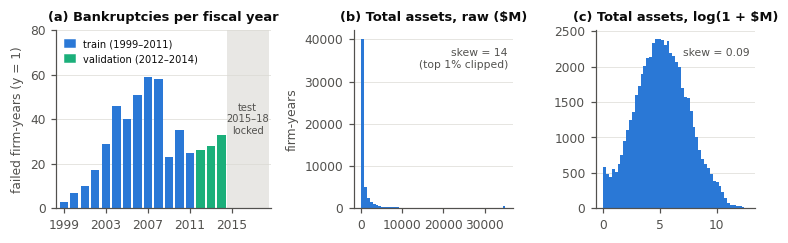

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.25), gridspec_kw=dict(width_ratios=[1.35, 1, 1]))
va_year = valid.groupby("year").y.sum()
ax[0].bar(by_year.index, by_year.fail, color=C_ALIVE, width=0.8)
ax[0].bar(va_year.index, va_year.values, color=C_THIRD, width=0.8)
ax[0].axvspan(2014.5, 2018.5, color=C_LOCK, alpha=0.6, lw=0)
ax[0].text(2016.5, 40, "test\n2015–18\nlocked", ha="center", va="center", fontsize=6.5, color=INK2)
ax[0].legend(handles=[Patch(color=C_ALIVE, label="train (1999–2011)"), Patch(color=C_THIRD, label="validation (2012–2014)")],
             loc="upper left", fontsize=6.5, handlelength=1)
ax[0].set_title("(a) Bankruptcies per fiscal year")
ax[0].set_ylabel("failed firm-years (y = 1)")
ax[0].set_xticks([1999, 2003, 2007, 2011, 2015]); ax[0].set_ylim(0, 80); ax[0].set_xlim(1998.3, 2018.7)
ax[0].grid(axis="x", visible=False)

ta = train.total_assets.clip(lower=0)
ax[1].hist(ta.clip(upper=ta.quantile(0.99)), bins=50, color=C_ALIVE)
ax[1].set_title("(b) Total assets, raw ($M)"); ax[1].set_ylabel("firm-years")
ax[1].text(0.97, 0.9, f"skew = {ta.skew():.0f}\n(top 1% clipped)", transform=ax[1].transAxes, ha="right", va="top", fontsize=7, color=INK2)
lta = np.log1p(ta)
ax[2].hist(lta, bins=50, color=C_ALIVE)
ax[2].set_title("(c) Total assets, log(1 + $M)")
ax[2].text(0.97, 0.9, f"skew = {lta.skew():.2f}", transform=ax[2].transAxes, ha="right", va="top", fontsize=7, color=INK2)
for a in ax[1:]:
    a.grid(axis="x", visible=False)
fig.tight_layout(w_pad=1.2)
fig.savefig("figures/fig1_problem_shape.png", dpi=300, bbox_inches="tight")

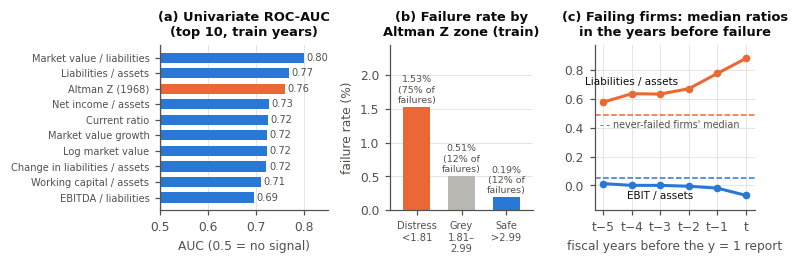

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.45), gridspec_kw=dict(width_ratios=[1.0, 0.85, 0.95]))
top = uni.head(10).iloc[::-1]
ax[0].barh(top.feature, top.AUC - 0.5, left=0.5, height=0.65,
           color=[C_FAIL if f == "Altman Z (1968)" else C_ALIVE for f in top.feature])
ax[0].set_xlim(0.5, max(0.85, top.AUC.max() + 0.03)); ax[0].axvline(0.5, color=INK2, lw=0.8)
for yv, a_ in enumerate(top.AUC):
    ax[0].text(a_ + 0.005, yv, f"{a_:.2f}", va="center", fontsize=6.5, color=INK2)
ax[0].set_title("(a) Univariate ROC-AUC\n(top 10, train years)")
ax[0].set_xlabel("AUC (0.5 = no signal)"); ax[0].grid(axis="y", visible=False); ax[0].tick_params(axis="y", labelsize=6.5)

zr = zt.rate * 100
ax[1].bar(range(3), zr, color=[C_FAIL, "#b9b8b2", C_ALIVE], width=0.6)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(["Distress\n<1.81", "Grey\n1.81–\n2.99", "Safe\n>2.99"], fontsize=6.5)
for i, (r, sh) in enumerate(zip(zr, zt["share of all failures"])):
    ax[1].text(i, r + 0.03, f"{r:.2f}%\n({sh:.0%} of\nfailures)", ha="center", va="bottom", fontsize=6.2, color=INK2)
ax[1].set_ylim(0, zr.max() * 1.6); ax[1].set_title("(b) Failure rate by\nAltman Z zone (train)"); ax[1].set_xlim(-0.6, 2.6)
ax[1].set_ylabel("failure rate (%)"); ax[1].grid(axis="x", visible=False)

t = traj.index.astype(int)
ax[2].plot(-t, traj["Liabilities / assets"], color=C_FAIL, lw=2, marker="o", ms=4)
ax[2].axhline(alive_ref["Liabilities / assets"], color=C_FAIL, lw=1, ls="--")
ax[2].plot(-t, traj["EBIT / assets"], color=C_ALIVE, lw=2, marker="o", ms=4)
ax[2].axhline(alive_ref["EBIT / assets"], color=C_ALIVE, lw=1, ls="--")
ax[2].text(-4, traj["Liabilities / assets"].iloc[1] + 0.05, "Liabilities / assets", fontsize=6.8, ha="center", va="bottom")
ax[2].text(-3, traj["EBIT / assets"].iloc[2] - 0.035, "EBIT / assets", fontsize=6.8, ha="center", va="top")
ax[2].text(-5.1, alive_ref["Liabilities / assets"] - 0.035, "- - never-failed firms' median", fontsize=6.3, color=INK2, va="top")
ax[2].set_ylim(-0.17, 0.97); ax[2].set_xlim(-5.3, 0.3)
ax[2].set_xticks(-np.arange(5, -1, -1)); ax[2].set_xticklabels([f"t−{k}" if k else "t" for k in range(5, -1, -1)])
ax[2].set_title("(c) Failing firms: median ratios\nin the years before failure")
ax[2].set_xlabel("fiscal years before the y = 1 report")
fig.tight_layout(w_pad=1.0)
fig.savefig("figures/fig2_signal.png", dpi=300, bbox_inches="tight")

figures written


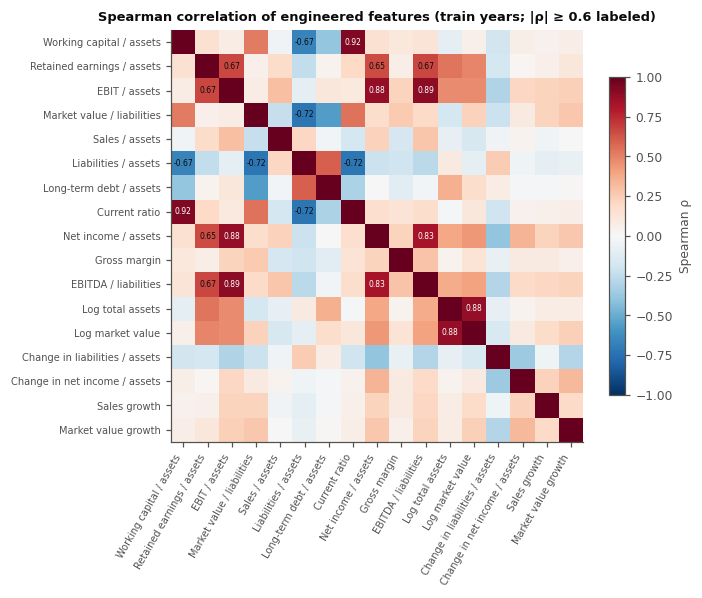

In [23]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_FEATS))); ax.set_xticklabels(NUM_FEATS, rotation=60, ha="right", fontsize=6.5)
ax.set_yticks(range(len(NUM_FEATS))); ax.set_yticklabels(NUM_FEATS, fontsize=6.5); ax.grid(False)
for i in range(len(NUM_FEATS)):
    for j in range(len(NUM_FEATS)):
        if i != j and abs(corr.iloc[i, j]) >= 0.6:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=5,
                    color="white" if abs(corr.iloc[i, j]) > 0.75 else INK)
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title("Spearman correlation of engineered features (train years; |ρ| ≥ 0.6 labeled)")
fig.tight_layout()
fig.savefig("figures/fig3_correlation.png", dpi=300, bbox_inches="tight")
print("figures written")